# Experiment 1: four SGD/HB data-scaling configurations

Fix

$$
s=0.3,\qquad \beta=4,
\qquad
D\in\{2000,4000,8000,16000,32000,64000,128000\}.
$$

Every configuration runs 100 independent trajectories and reports the mean
**final** excess loss. There is no bootstrap, confidence interval, best-iterate
selection, or minimum over the loss trajectory.

The number of optimization steps is now directly configurable for every group:

$$
K=\operatorname{round}(c_KD^{\kappa}).
$$

The batch size is then chosen automatically as

$$
B=\left\lfloor\frac{D}{K}\right\rfloor,
$$

so the actually used data budget satisfies $BK\le D$. Thus, changing
$c_K$ changes the finite-budget prefactor of the number of steps without
requiring any other code changes.

The four configurations are:

1. **SGD-large-search**: configurable $K=c_KD^\kappa$, with a learning-rate grid search.
2. **HB-large-opt**: configurable $K=c_KD^\kappa$, fixed Heavy-Ball parameter scaling.
3. **SGD-optimal-batch**: configurable $K=c_KD^\kappa$, fixed learning rate.
4. **HB-optimal-batch**: configurable $K=c_KD^\kappa$, fixed Heavy-Ball parameter scaling.

All tables, final-loss arrays, and figures are saved under the newly created
`mom_optimal` directory.

The data-scaling figure displays the experimental results as isolated markers, with no line connecting adjacent data points. For each configuration, the theoretical power-law line is anchored at the fourth data point, which is the middle point of the seven values in `D_LIST`. If that point is $(D_4,L_4)$ and the predicted loss exponent is $p$, the reference line is

$$
L_{\mathrm{theory}}(D)=L_4\left(\frac{D}{D_4}\right)^{-p}.
$$


## Theoretical default choices

Let

$$
x_\star=\frac{s}{s+1}.
$$

The default powers reproduce the original batch-size scalings. Since
$D=BK$, a batch scaling $B\asymp D^a$ corresponds to

$$
K\asymp D^{1-a}.
$$

Therefore the default step powers are

$$
\kappa_{\rm large}=1-2x_\star,
\qquad
\kappa_{\rm optimal}=1-x_\star.
$$

The constants and powers can both be changed in the configuration cell. For
example,

```python
HB_LARGE_STEP_CONSTANT = 2.0
HB_LARGE_STEP_EXPONENT = 1.0 - LARGE_BATCH_EXPONENT
```

uses approximately twice as many Heavy-Ball steps while keeping the same
asymptotic power. Changing the step power changes the implied batch exponent
$a=1-\kappa$; in that case the original reference theory exponent may no
longer apply, and the notebook records it as `NaN`.


In [1]:
import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

# =============================================================================
# Global numerical and plotting settings
# =============================================================================

torch.set_default_dtype(torch.float64)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.figsize": (5, 4),
    "legend.fontsize": 10,
    "legend.handlelength": 1,
})

# =============================================================================
# 1. Configuration
# =============================================================================

BETA = 4.0
S_VALUE = 0.3
SIGMA = 0.1

DIM = 4096
N_RUNS = 100
D_LIST = [2000, 4000, 8000, 16000, 32000, 64000, 128000]
BASE_SEED = 20260718

# Create the requested output directory.
OUTPUT_DIR = Path("mom_optimal")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X_STAR = S_VALUE / (S_VALUE + 1.0)
LARGE_BATCH_EXPONENT = 2.0 * X_STAR
OPTIMAL_BATCH_EXPONENT = X_STAR

# =============================================================================
# STEP-SCALING CONTROLS: edit this block to choose K = c_K * D^kappa.
#
# The four groups have separate controls, so SGD and momentum can use
# different constants (and, if desired, different powers).
#
# After K is constructed, the code sets B = floor(D / K), ensuring B*K <= D.
# =============================================================================

# SGD with the original large-batch scaling.
SGD_LARGE_STEP_CONSTANT = 1.0
SGD_LARGE_STEP_EXPONENT = 1.0 - LARGE_BATCH_EXPONENT

# Heavy Ball / momentum with the original large-batch scaling.
HB_LARGE_STEP_CONSTANT = 1.0
HB_LARGE_STEP_EXPONENT = 1.0 - LARGE_BATCH_EXPONENT

# SGD with the original optimal-batch scaling.
SGD_OPTIMAL_STEP_CONSTANT = 1.0
SGD_OPTIMAL_STEP_EXPONENT = 1.0 - OPTIMAL_BATCH_EXPONENT

# Heavy Ball / momentum with the original optimal-batch scaling.
HB_OPTIMAL_STEP_CONSTANT = 1.05
HB_OPTIMAL_STEP_EXPONENT = 1.0 - OPTIMAL_BATCH_EXPONENT

# -------------------------------------------------------------------------
# SGD-large-search: search eta separately at every D.
# -------------------------------------------------------------------------

SGD_LARGE_LR_GRID = [
    0.50,
]

# -------------------------------------------------------------------------
# HB-large-opt: eta ~ D^0, 1-rho ~ D^{-x_star}.
# -------------------------------------------------------------------------

HB_LARGE_ETA_CONSTANT = 0.10
HB_LARGE_ETA_EXPONENT = 0.0
HB_LARGE_GAP_CONSTANT = 1.0
HB_LARGE_GAP_EXPONENT = X_STAR

# -------------------------------------------------------------------------
# SGD-optimal-batch: eta ~ D^0, with no learning-rate search.
# -------------------------------------------------------------------------

SGD_OPTIMAL_ETA = 0.10

# -------------------------------------------------------------------------
# HB-optimal-batch: eta ~ D^{-x_star}, 1-rho ~ D^{-x_star}.
# -------------------------------------------------------------------------

HB_OPTIMAL_ETA_CONSTANT = 0.10
HB_OPTIMAL_ETA_EXPONENT = X_STAR
HB_OPTIMAL_GAP_CONSTANT = 1.0
HB_OPTIMAL_GAP_EXPONENT = X_STAR

# Reference predicted loss exponents.  The theoretical line has slope -p
# on the log-log plot.  These values can also be edited directly when a
# custom K exponent leads to a different theoretical prediction.
P_SGD_LARGE = S_VALUE * (1.0 - LARGE_BATCH_EXPONENT)
P_OPTIMAL = X_STAR

SGD_LARGE_THEORY_EXPONENT = P_SGD_LARGE
HB_LARGE_THEORY_EXPONENT = P_OPTIMAL
SGD_OPTIMAL_THEORY_EXPONENT = P_OPTIMAL
HB_OPTIMAL_THEORY_EXPONENT = P_OPTIMAL

# Use the fourth experimental point, the middle of the seven D values,
# as the anchor of every theoretical line. Python uses zero-based indexing,
# so index 3 means the fourth point.
THEORY_ANCHOR_INDEX = 3

GROUP_ORDER = [
    "sgd_large_search",
    "hb_large_opt",
    "sgd_optimal_batch",
    "hb_optimal_batch",
]

STEP_CONSTANTS = {
    "sgd_large_search": SGD_LARGE_STEP_CONSTANT,
    "hb_large_opt": HB_LARGE_STEP_CONSTANT,
    "sgd_optimal_batch": SGD_OPTIMAL_STEP_CONSTANT,
    "hb_optimal_batch": HB_OPTIMAL_STEP_CONSTANT,
}

STEP_EXPONENTS = {
    "sgd_large_search": SGD_LARGE_STEP_EXPONENT,
    "hb_large_opt": HB_LARGE_STEP_EXPONENT,
    "sgd_optimal_batch": SGD_OPTIMAL_STEP_EXPONENT,
    "hb_optimal_batch": HB_OPTIMAL_STEP_EXPONENT,
}

REFERENCE_STEP_EXPONENTS = {
    "sgd_large_search": 1.0 - LARGE_BATCH_EXPONENT,
    "hb_large_opt": 1.0 - LARGE_BATCH_EXPONENT,
    "sgd_optimal_batch": 1.0 - OPTIMAL_BATCH_EXPONENT,
    "hb_optimal_batch": 1.0 - OPTIMAL_BATCH_EXPONENT,
}

THEORY_EXPONENTS = {
    "sgd_large_search": SGD_LARGE_THEORY_EXPONENT,
    "hb_large_opt": HB_LARGE_THEORY_EXPONENT,
    "sgd_optimal_batch": SGD_OPTIMAL_THEORY_EXPONENT,
    "hb_optimal_batch": HB_OPTIMAL_THEORY_EXPONENT,
}


def step_scaling_text(group):
    c_k = STEP_CONSTANTS[group]
    kappa = STEP_EXPONENTS[group]
    return rf"$K={c_k:g}D^{{{kappa:.3f}}}$"


GROUP_LABELS = {
    "sgd_large_search": (
        f"SGD large, {step_scaling_text('sgd_large_search')}, LR search"
    ),
    "hb_large_opt": (
        f"HB large, {step_scaling_text('hb_large_opt')}"
    ),
    "sgd_optimal_batch": (
        f"SGD optimal, {step_scaling_text('sgd_optimal_batch')}, fixed LR"
    ),
    "hb_optimal_batch": (
        f"HB optimal, {step_scaling_text('hb_optimal_batch')}"
    ),
}

print(f"beta={BETA:g}, s={S_VALUE:g}, sigma={SIGMA:g}, dim={DIM}")
print(f"D values={D_LIST}, runs per configuration={N_RUNS}")
print(f"x_star=s/(s+1)={X_STAR:.9f}")
print("Step scalings K = c_K * D^kappa:")
for group in GROUP_ORDER:
    print(
        f"  {group}: c_K={STEP_CONSTANTS[group]:g}, "
        f"kappa={STEP_EXPONENTS[group]:.9f}"
    )
print(f"SGD-large LR grid={SGD_LARGE_LR_GRID}")
print(f"output directory={OUTPUT_DIR.resolve()}")


beta=4, s=0.3, sigma=0.1, dim=4096
D values=[2000, 4000, 8000, 16000, 32000, 64000, 128000], runs per configuration=100
x_star=s/(s+1)=0.230769231
Step scalings K = c_K * D^kappa:
  sgd_large_search: c_K=1, kappa=0.538461538
  hb_large_opt: c_K=1, kappa=0.538461538
  sgd_optimal_batch: c_K=1, kappa=0.769230769
  hb_optimal_batch: c_K=1.05, kappa=0.769230769
SGD-large LR grid=[0.5]
output directory=/home/jnwang/momentum/data_scaling/mom_optimal


In [2]:

# =============================================================================
# 2. Power-law kernel-regression problem
# =============================================================================

def build_problem(dim=DIM, beta=BETA, s=S_VALUE, dtype=np.float32):
    """
    Spectrum:
        lambda_j ~ j^{-beta}

    Source condition:
        lambda_j * theta_star_j^2 ~ j^{-1-beta*s}

    Hence:
        theta_star_j^2 ~ j^{-1-beta*(s-1)}.
    """
    if dim < 1:
        raise ValueError("DIM must be positive.")
    if beta <= 1:
        raise ValueError("BETA must be greater than 1.")
    if s <= 0:
        raise ValueError("S_VALUE must be positive.")

    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    theta_squared = j ** (-(1.0 + beta * (s - 1.0)))
    theta_star = np.sqrt(theta_squared)

    return lam.astype(dtype), theta_star.astype(dtype)


def excess_loss_batch(delta, lam):
    return 0.5 * np.sum(
        lam[None, :] * delta * delta,
        axis=1,
        dtype=np.float64,
    )


def excess_loss_single(delta, lam):
    return float(0.5 * np.sum(lam * delta * delta, dtype=np.float64))


LAM, THETA_STAR = build_problem()

print(f"lambda_1={LAM[0]:.6e}")
print(f"lambda_DIM={LAM[-1]:.6e}")
print(f"initial excess loss={excess_loss_single(-THETA_STAR, LAM):.6e}")


lambda_1=1.000000e+00
lambda_DIM=3.552714e-15
initial excess loss=7.452524e-01



## Stochastic-gradient model

Both algorithms use

$$
g_t=He_t+\xi_t,
\qquad
\operatorname{Cov}(\xi_t\mid e_t)
=
\frac{\mathcal E_t+\sigma^2}{B}H.
$$

For Heavy Ball,

$$
e_{t+1}=e_t-\eta g_t+\rho(e_t-e_{t-1}).
$$

All 100 trajectories are updated together in vectorized form. Only the loss after the final update is returned.


In [3]:

# =============================================================================
# 3. Vectorized SGD / Heavy-Ball simulator
# =============================================================================

def stable_seed(*items):
    text = "|".join(str(item) for item in items)
    return (BASE_SEED + zlib.crc32(text.encode("utf-8"))) % (2**32 - 1)


def run_optimizer(
    algo,
    batch_size,
    num_steps,
    eta,
    rho,
    lam=LAM,
    theta_star=THETA_STAR,
    sigma=SIGMA,
    n_runs=N_RUNS,
    seed=0,
):
    """Return one final excess loss for each independent trajectory."""
    if algo not in {"sgd", "hb"}:
        raise ValueError(f"Unknown algorithm: {algo}")
    if batch_size < 1 or num_steps < 1 or n_runs < 1:
        raise ValueError("batch_size, num_steps, and n_runs must be positive.")
    if not (0.0 < eta < 1.0):
        raise ValueError(f"eta must lie in (0,1), got {eta}.")
    if not (0.0 <= rho < 1.0):
        raise ValueError(f"rho must lie in [0,1), got {rho}.")

    rng = np.random.default_rng(seed)
    runs = int(n_runs)
    dim = lam.size

    delta = np.broadcast_to(-theta_star, (runs, dim)).copy()
    delta_previous = delta.copy()

    lam_row = lam[None, :]
    sqrt_lam_row = np.sqrt(lam).astype(np.float32)[None, :]

    for _ in range(num_steps):
        current_loss = excess_loss_batch(delta, lam)

        gaussian = rng.standard_normal(size=(runs, dim)).astype(
            np.float32,
            copy=False,
        )
        noise_scale = np.sqrt(
            (current_loss + sigma**2) / batch_size
        ).astype(np.float32)
        noise = noise_scale[:, None] * sqrt_lam_row * gaussian

        gradient = lam_row * delta + noise

        if algo == "sgd":
            next_delta = delta - eta * gradient
        else:
            velocity = delta - delta_previous
            next_delta = delta - eta * gradient + rho * velocity

        delta_previous, delta = delta, next_delta.astype(
            np.float32,
            copy=False,
        )

    final_losses = excess_loss_batch(delta, lam)

    if np.any(~np.isfinite(final_losses)):
        raise FloatingPointError(
            f"Non-finite final loss for algo={algo}, B={batch_size}, "
            f"K={num_steps}, eta={eta}, rho={rho}."
        )

    return final_losses


In [4]:
# =============================================================================
# 4. Finite-D schedules
# =============================================================================

def make_base_schedule(D, *, group, step_constant, step_exponent):
    """Construct K = round(c_K D^kappa), then B = floor(D / K)."""
    if D < 1:
        raise ValueError("D must be positive.")
    if step_constant <= 0:
        raise ValueError("The step constant c_K must be positive.")
    if step_exponent < 0:
        raise ValueError("The step exponent kappa must be nonnegative.")

    requested_num_steps = max(
        1,
        int(round(step_constant * D ** step_exponent)),
    )

    # Since D is the total data budget and B >= 1, K cannot exceed D.
    num_steps = min(int(D), requested_num_steps)
    batch_size = max(1, int(D // num_steps))
    used_budget = batch_size * num_steps

    return {
        "D": int(D),
        "B": int(batch_size),
        "K": int(num_steps),
        "requested_K": int(requested_num_steps),
        "K_was_clipped": bool(requested_num_steps > D),
        "used_budget": int(used_budget),
        "used_fraction": float(used_budget / D),
        "step_constant": float(step_constant),
        "step_exponent": float(step_exponent),
        # Because D = BK, K ~ D^kappa implies B ~ D^(1-kappa).
        "a": float(1.0 - step_exponent),
        "group": group,
    }


def make_sgd_large_base_schedule(D):
    return make_base_schedule(
        D,
        group="sgd_large_search",
        step_constant=SGD_LARGE_STEP_CONSTANT,
        step_exponent=SGD_LARGE_STEP_EXPONENT,
    )


def make_sgd_optimal_schedule(D):
    schedule = make_base_schedule(
        D,
        group="sgd_optimal_batch",
        step_constant=SGD_OPTIMAL_STEP_CONSTANT,
        step_exponent=SGD_OPTIMAL_STEP_EXPONENT,
    )
    schedule.update(
        {
            "algorithm": "sgd",
            "eta": float(SGD_OPTIMAL_ETA),
            "rho": 0.0,
            "one_minus_rho": 1.0,
            "b": 0.0,
            "c": 0.0,
            "K_times_gap": float(schedule["K"]),
            "eta_over_gap": float(SGD_OPTIMAL_ETA),
            "stability_ratio": float(
                SGD_OPTIMAL_ETA / schedule["B"]
            ),
            "p_theory": float(THEORY_EXPONENTS["sgd_optimal_batch"]),
        }
    )
    return schedule


def make_hb_schedule(
    D,
    *,
    group,
    step_constant,
    step_exponent,
    eta_constant,
    eta_exponent,
    gap_constant,
    gap_exponent,
):
    schedule = make_base_schedule(
        D,
        group=group,
        step_constant=step_constant,
        step_exponent=step_exponent,
    )

    eta = eta_constant * D ** (-eta_exponent)
    one_minus_rho = min(
        1.0,
        gap_constant * D ** (-gap_exponent),
    )
    rho = 1.0 - one_minus_rho

    schedule.update(
        {
            "algorithm": "hb",
            "eta": float(eta),
            "rho": float(rho),
            "one_minus_rho": float(one_minus_rho),
            "b": float(gap_exponent),
            "c": float(eta_exponent),
            "K_times_gap": float(
                schedule["K"] * one_minus_rho
            ),
            "eta_over_gap": float(
                eta / one_minus_rho
            ),
            "eta_over_gap_squared": float(
                eta / one_minus_rho**2
            ),
            "stability_ratio": float(
                eta / (schedule["B"] * one_minus_rho)
            ),
            "p_theory": float(THEORY_EXPONENTS[group]),
        }
    )
    return schedule


def make_hb_large_schedule(D):
    return make_hb_schedule(
        D,
        group="hb_large_opt",
        step_constant=HB_LARGE_STEP_CONSTANT,
        step_exponent=HB_LARGE_STEP_EXPONENT,
        eta_constant=HB_LARGE_ETA_CONSTANT,
        eta_exponent=HB_LARGE_ETA_EXPONENT,
        gap_constant=HB_LARGE_GAP_CONSTANT,
        gap_exponent=HB_LARGE_GAP_EXPONENT,
    )


def make_hb_optimal_schedule(D):
    return make_hb_schedule(
        D,
        group="hb_optimal_batch",
        step_constant=HB_OPTIMAL_STEP_CONSTANT,
        step_exponent=HB_OPTIMAL_STEP_EXPONENT,
        eta_constant=HB_OPTIMAL_ETA_CONSTANT,
        eta_exponent=HB_OPTIMAL_ETA_EXPONENT,
        gap_constant=HB_OPTIMAL_GAP_CONSTANT,
        gap_exponent=HB_OPTIMAL_GAP_EXPONENT,
    )


SCHEDULE_PREVIEW = pd.concat(
    [
        pd.DataFrame(
            [
                {
                    **make_sgd_large_base_schedule(D),
                    "algorithm": "sgd",
                    "eta": np.nan,
                    "rho": 0.0,
                    "one_minus_rho": 1.0,
                    "b": 0.0,
                    "c": 0.0,
                    "p_theory": THEORY_EXPONENTS["sgd_large_search"],
                }
                for D in D_LIST
            ]
        ),
        pd.DataFrame(
            [make_hb_large_schedule(D) for D in D_LIST]
        ),
        pd.DataFrame(
            [make_sgd_optimal_schedule(D) for D in D_LIST]
        ),
        pd.DataFrame(
            [make_hb_optimal_schedule(D) for D in D_LIST]
        ),
    ],
    ignore_index=True,
)

preview_columns = [
    "group",
    "D",
    "step_constant",
    "step_exponent",
    "requested_K",
    "K",
    "B",
    "used_budget",
    "used_fraction",
    "eta",
    "rho",
    "p_theory",
]
display(SCHEDULE_PREVIEW[preview_columns])


,group,D,step_constant,step_exponent,requested_K,K,B,used_budget,used_fraction,eta,rho,p_theory
0,sgd_large_search,2000,1.00,0.538462,60,60,33,1980,0.990000,NaN,0.000000,0.161538
1,sgd_large_search,4000,1.00,0.538462,87,87,45,3915,0.978750,NaN,0.000000,0.161538
2,sgd_large_search,8000,1.00,0.538462,126,126,63,7938,0.992250,NaN,0.000000,0.161538
3,sgd_large_search,16000,1.00,0.538462,184,184,86,15824,0.989000,NaN,0.000000,0.161538
4,sgd_large_search,32000,1.00,0.538462,267,267,119,31773,0.992906,NaN,0.000000,0.161538
5,sgd_large_search,64000,1.00,0.538462,387,387,165,63855,0.997734,NaN,0.000000,0.161538
6,sgd_large_search,128000,1.00,0.538462,562,562,227,127574,0.996672,NaN,0.000000,0.161538
7,hb_large_opt,2000,1.00,0.538462,60,60,33,1980,0.990000,0.100000,0.826929,0.230769
8,hb_large_opt,4000,1.00,0.538462,87,87,45,3915,0.978750,0.100000,0.852512,0.230769
9,hb_large_opt,8000,1.00,0.538462,126,126,63,7938,0.992250,0.100000,0.874314,0.230769


In [5]:
# =============================================================================
# 5. Run all four configurations
#
# Only SGD-large-search searches its learning rate.
# Every candidate and every fixed configuration runs N_RUNS trajectories.
# The metric is always the mean final excess loss.
# =============================================================================

RESULTS = {group: [] for group in GROUP_ORDER}
SELECTED_SCHEDULES = {group: [] for group in GROUP_ORDER}

SGD_SEARCH_ROWS = []

# Shape:
#   [number of D values, number of candidate learning rates, number of runs]
#
# It stores all candidate-level final losses, not only the selected candidate.
SGD_SEARCH_ALL_FINAL_LOSSES = np.full(
    (
        len(D_LIST),
        len(SGD_LARGE_LR_GRID),
        N_RUNS,
    ),
    np.nan,
    dtype=np.float64,
)

# -------------------------------------------------------------------------
# 5.1 SGD-large-search
# -------------------------------------------------------------------------

for d_index, D in enumerate(D_LIST):
    base_schedule = make_sgd_large_base_schedule(D)

    # Common random numbers across learning-rate candidates at fixed D.
    common_seed = stable_seed(
        "experiment1",
        "sgd_large_search",
        D,
    )

    best_mean = np.inf
    best_eta = None
    best_losses = None

    print(
        f"\nSGD-large search: D={D}, "
        f"K={base_schedule['K']} "
        f"(c_K={base_schedule['step_constant']:g}, "
        f"kappa={base_schedule['step_exponent']:.4f}), "
        f"B={base_schedule['B']}"
    )

    for eta_index, eta in enumerate(SGD_LARGE_LR_GRID):
        start_time = time.time()

        try:
            final_losses = run_optimizer(
                algo="sgd",
                batch_size=base_schedule["B"],
                num_steps=base_schedule["K"],
                eta=float(eta),
                rho=0.0,
                n_runs=N_RUNS,
                seed=common_seed,
            )
            mean_final_loss = float(np.mean(final_losses))
            status = "ok"

            SGD_SEARCH_ALL_FINAL_LOSSES[
                d_index,
                eta_index,
                :,
            ] = final_losses
        except (FloatingPointError, ValueError) as error:
            final_losses = None
            mean_final_loss = np.inf
            status = f"failed: {error}"

        elapsed = time.time() - start_time

        SGD_SEARCH_ROWS.append(
            {
                "group": "sgd_large_search",
                "D": int(D),
                "B": base_schedule["B"],
                "K": base_schedule["K"],
                "step constant": base_schedule["step_constant"],
                "step exponent": base_schedule["step_exponent"],
                "eta": float(eta),
                "mean final loss": mean_final_loss,
                "status": status,
                "elapsed seconds": elapsed,
            }
        )

        print(
            f"  eta={eta:.4f} | "
            f"mean final loss={mean_final_loss:.6e} | "
            f"{status} | {elapsed:.2f}s"
        )

        if mean_final_loss < best_mean:
            best_mean = mean_final_loss
            best_eta = float(eta)
            best_losses = final_losses

    if best_losses is None:
        raise RuntimeError(
            f"All SGD learning-rate candidates failed for D={D}."
        )

    selected_schedule = {
        **base_schedule,
        "group": "sgd_large_search",
        "algorithm": "sgd",
        "eta": best_eta,
        "rho": 0.0,
        "one_minus_rho": 1.0,
        "b": 0.0,
        "c": 0.0,
        "K_times_gap": float(base_schedule["K"]),
        "eta_over_gap": best_eta,
        "stability_ratio": float(
            best_eta / base_schedule["B"]
        ),
        "p_theory": float(P_SGD_LARGE),
    }

    RESULTS["sgd_large_search"].append(best_losses)
    SELECTED_SCHEDULES["sgd_large_search"].append(
        selected_schedule
    )

    print(
        f"  selected eta={best_eta:.4f} | "
        f"best mean final loss={best_mean:.6e}"
    )


# -------------------------------------------------------------------------
# 5.2 The three fixed, non-searched configurations
# -------------------------------------------------------------------------

FIXED_GROUPS = [
    (
        "hb_large_opt",
        "hb",
        make_hb_large_schedule,
    ),
    (
        "sgd_optimal_batch",
        "sgd",
        make_sgd_optimal_schedule,
    ),
    (
        "hb_optimal_batch",
        "hb",
        make_hb_optimal_schedule,
    ),
]

for group, algorithm, schedule_function in FIXED_GROUPS:
    for D in D_LIST:
        schedule = schedule_function(D)
        start_time = time.time()

        final_losses = run_optimizer(
            algo=algorithm,
            batch_size=schedule["B"],
            num_steps=schedule["K"],
            eta=schedule["eta"],
            rho=schedule["rho"],
            n_runs=N_RUNS,
            seed=stable_seed("experiment1", group, D),
        )

        elapsed = time.time() - start_time
        mean_final_loss = float(np.mean(final_losses))

        RESULTS[group].append(final_losses)
        SELECTED_SCHEDULES[group].append(schedule)

        print(
            f"\n{group}: D={D:6d} | "
            f"K={schedule['K']:5d} "
            f"(c_K={schedule['step_constant']:g}, "
            f"kappa={schedule['step_exponent']:.4f}) | "
            f"B={schedule['B']:4d} | "
            f"eta={schedule['eta']:.6f} | "
            f"rho={schedule['rho']:.6f} | "
            f"mean final loss={mean_final_loss:.6e} | "
            f"{elapsed:.2f}s"
        )


SGD_SEARCH_TABLE = pd.DataFrame(SGD_SEARCH_ROWS)

selected_eta_by_D = {
    schedule["D"]: schedule["eta"]
    for schedule in SELECTED_SCHEDULES["sgd_large_search"]
}
SGD_SEARCH_TABLE["selected"] = [
    np.isclose(row.eta, selected_eta_by_D[int(row.D)])
    for row in SGD_SEARCH_TABLE.itertuples(index=False)
]

display(SGD_SEARCH_TABLE)


SGD-large search: D=2000, K=60 (c_K=1, kappa=0.5385), B=33
  eta=0.5000 | mean final loss=1.089354e-01 | ok | 0.57s
  selected eta=0.5000 | best mean final loss=1.089354e-01

SGD-large search: D=4000, K=87 (c_K=1, kappa=0.5385), B=45
  eta=0.5000 | mean final loss=9.811749e-02 | ok | 0.69s
  selected eta=0.5000 | best mean final loss=9.811749e-02

SGD-large search: D=8000, K=126 (c_K=1, kappa=0.5385), B=63
  eta=0.5000 | mean final loss=8.808962e-02 | ok | 0.99s
  selected eta=0.5000 | best mean final loss=8.808962e-02

SGD-large search: D=16000, K=184 (c_K=1, kappa=0.5385), B=86
  eta=0.5000 | mean final loss=7.851932e-02 | ok | 1.45s
  selected eta=0.5000 | best mean final loss=7.851932e-02

SGD-large search: D=32000, K=267 (c_K=1, kappa=0.5385), B=119
  eta=0.5000 | mean final loss=6.997692e-02 | ok | 2.11s
  selected eta=0.5000 | best mean final loss=6.997692e-02

SGD-large search: D=64000, K=387 (c_K=1, kappa=0.5385), B=165
  eta=0.5000 | mean final loss=6.257614e-02 | ok | 3.04s

,group,D,B,K,step constant,step exponent,eta,mean final loss,status,elapsed seconds,selected
0,sgd_large_search,2000,33,60,1.0,0.538462,0.5,0.108935,ok,0.572198,True
1,sgd_large_search,4000,45,87,1.0,0.538462,0.5,0.098117,ok,0.690939,True
2,sgd_large_search,8000,63,126,1.0,0.538462,0.5,0.088090,ok,0.993852,True
3,sgd_large_search,16000,86,184,1.0,0.538462,0.5,0.078519,ok,1.451343,True
4,sgd_large_search,32000,119,267,1.0,0.538462,0.5,0.069977,ok,2.105490,True
5,sgd_large_search,64000,165,387,1.0,0.538462,0.5,0.062576,ok,3.044147,True
6,sgd_large_search,128000,227,562,1.0,0.538462,0.5,0.056003,ok,4.426835,True


In [6]:
# =============================================================================
# 6. Mean final losses and log-log fits
# =============================================================================

def fit_exponent(D_values, mean_losses):
    D_values = np.asarray(D_values, dtype=np.float64)
    mean_losses = np.asarray(mean_losses, dtype=np.float64)

    if np.any(~np.isfinite(mean_losses)):
        raise ValueError("Mean losses must be finite.")
    if np.any(mean_losses <= 0):
        raise ValueError("Mean losses must be positive.")

    slope, intercept = np.polyfit(
        np.log(D_values),
        np.log(mean_losses),
        deg=1,
    )
    return -float(slope), float(intercept)


MEAN_CURVES = {}
summary_rows = []
result_rows = []

for group in GROUP_ORDER:
    means = np.asarray(
        [
            float(np.mean(final_losses))
            for final_losses in RESULTS[group]
        ],
        dtype=np.float64,
    )
    MEAN_CURVES[group] = means

    measured_exponent, intercept = fit_exponent(
        D_LIST,
        means,
    )

    summary_rows.append(
        {
            "group": group,
            "label": GROUP_LABELS[group],
            "theory exponent": THEORY_EXPONENTS[group],
            "measured exponent": measured_exponent,
            "log-fit intercept": intercept,
        }
    )

    for D, final_losses, schedule in zip(
        D_LIST,
        RESULTS[group],
        SELECTED_SCHEDULES[group],
    ):
        result_rows.append(
            {
                "group": group,
                "label": GROUP_LABELS[group],
                "algorithm": schedule["algorithm"],
                "D": int(D),
                "B": schedule["B"],
                "K": schedule["K"],
                "step constant": schedule["step_constant"],
                "step exponent": schedule["step_exponent"],
                "used budget": schedule["used_budget"],
                "eta": schedule["eta"],
                "rho": schedule["rho"],
                "mean final loss": float(
                    np.mean(final_losses)
                ),
                "theory exponent": schedule["p_theory"],
            }
        )


SLOPE_SUMMARY = pd.DataFrame(summary_rows)
RESULT_TABLE = pd.DataFrame(result_rows)

SELECTED_SCHEDULE_TABLE = pd.concat(
    [
        pd.DataFrame(SELECTED_SCHEDULES[group])
        for group in GROUP_ORDER
    ],
    ignore_index=True,
)

print("Mean final losses:")
display(RESULT_TABLE)

print("Measured exponents:")
display(SLOPE_SUMMARY)

print("Schedules:")
display(SELECTED_SCHEDULE_TABLE)

Mean final losses:


,group,label,algorithm,D,B,K,step constant,step exponent,used budget,eta,rho,mean final loss,theory exponent
0,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",sgd,2000,33,60,1.00,0.538462,1980,0.500000,0.000000,0.108935,0.161538
1,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",sgd,4000,45,87,1.00,0.538462,3915,0.500000,0.000000,0.098117,0.161538
2,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",sgd,8000,63,126,1.00,0.538462,7938,0.500000,0.000000,0.088090,0.161538
3,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",sgd,16000,86,184,1.00,0.538462,15824,0.500000,0.000000,0.078519,0.161538
4,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",sgd,32000,119,267,1.00,0.538462,31773,0.500000,0.000000,0.069977,0.161538
5,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",sgd,64000,165,387,1.00,0.538462,63855,0.500000,0.000000,0.062576,0.161538
6,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",sgd,128000,227,562,1.00,0.538462,127574,0.500000,0.000000,0.056003,0.161538
7,hb_large_opt,"HB large, $K=1D^{0.538}$",hb,2000,33,60,1.00,0.538462,1980,0.100000,0.826929,0.105569,0.230769
8,hb_large_opt,"HB large, $K=1D^{0.538}$",hb,4000,45,87,1.00,0.538462,3915,0.100000,0.852512,0.091005,0.230769
9,hb_large_opt,"HB large, $K=1D^{0.538}$",hb,8000,63,126,1.00,0.538462,7938,0.100000,0.874314,0.076926,0.230769


Measured exponents:


,group,label,theory exponent,measured exponent,log-fit intercept
0,sgd_large_search,"SGD large, $K=1D^{0.538}$, LR search",0.161538,0.161056,-0.987455
1,hb_large_opt,"HB large, $K=1D^{0.538}$",0.230769,0.232478,-0.475962
2,sgd_optimal_batch,"SGD optimal, $K=1D^{0.769}$, fixed LR",0.230769,0.231079,-0.494162
3,hb_optimal_batch,"HB optimal, $K=1.05D^{0.769}$",0.230769,0.231606,-0.504058


Schedules:


,D,B,K,requested_K,K_was_clipped,used_budget,used_fraction,step_constant,step_exponent,a,...,eta,rho,one_minus_rho,b,c,K_times_gap,eta_over_gap,stability_ratio,p_theory,eta_over_gap_squared
0,2000,33,60,60,False,1980,0.990000,1.00,0.538462,0.461538,...,0.500000,0.000000,1.000000,0.000000,0.000000,60.000000,0.500000,0.015152,0.161538,NaN
1,4000,45,87,87,False,3915,0.978750,1.00,0.538462,0.461538,...,0.500000,0.000000,1.000000,0.000000,0.000000,87.000000,0.500000,0.011111,0.161538,NaN
2,8000,63,126,126,False,7938,0.992250,1.00,0.538462,0.461538,...,0.500000,0.000000,1.000000,0.000000,0.000000,126.000000,0.500000,0.007937,0.161538,NaN
3,16000,86,184,184,False,15824,0.989000,1.00,0.538462,0.461538,...,0.500000,0.000000,1.000000,0.000000,0.000000,184.000000,0.500000,0.005814,0.161538,NaN
4,32000,119,267,267,False,31773,0.992906,1.00,0.538462,0.461538,...,0.500000,0.000000,1.000000,0.000000,0.000000,267.000000,0.500000,0.004202,0.161538,NaN
5,64000,165,387,387,False,63855,0.997734,1.00,0.538462,0.461538,...,0.500000,0.000000,1.000000,0.000000,0.000000,387.000000,0.500000,0.003030,0.161538,NaN
6,128000,227,562,562,False,127574,0.996672,1.00,0.538462,0.461538,...,0.500000,0.000000,1.000000,0.000000,0.000000,562.000000,0.500000,0.002203,0.161538,NaN
7,2000,33,60,60,False,1980,0.990000,1.00,0.538462,0.461538,...,0.100000,0.826929,0.173071,0.230769,0.000000,10.384249,0.577798,0.017509,0.230769,3.338507
8,4000,45,87,87,False,3915,0.978750,1.00,0.538462,0.461538,...,0.100000,0.852512,0.147488,0.230769,0.000000,12.831418,0.678023,0.015067,0.230769,4.597156
9,8000,63,126,126,False,7938,0.992250,1.00,0.538462,0.461538,...,0.100000,0.874314,0.125686,0.230769,0.000000,15.836437,0.795634,0.012629,0.230769,6.330327


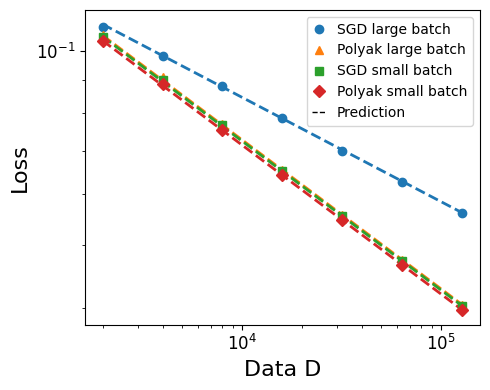

In [7]:
# =============================================================================
# 7. Plot experimental points and prediction lines
# =============================================================================

from matplotlib.lines import Line2D

MARKERS = {
    "sgd_large_search": "o",
    "hb_large_opt": "^",
    "sgd_optimal_batch": "s",
    "hb_optimal_batch": "D",
}

POINT_LABELS = {
    "sgd_large_search": "SGD large batch",
    "hb_large_opt": "Polyak large batch",
    "sgd_optimal_batch": "SGD small batch",
    "hb_optimal_batch": "Polyak small batch",
}

D_ARRAY = np.asarray(D_LIST, dtype=np.float64)

if not 0 <= THEORY_ANCHOR_INDEX < len(D_ARRAY):
    raise IndexError(
        "THEORY_ANCHOR_INDEX must identify an existing point in D_LIST."
    )

plt.figure()

for group in GROUP_ORDER:
    mean_losses = np.asarray(
        MEAN_CURVES[group],
        dtype=np.float64,
    )

    # Experimental results: points only, without connecting lines.
    point_handle, = plt.plot(
        D_ARRAY,
        mean_losses,
        linestyle="None",
        marker=MARKERS[group],
        label=POINT_LABELS[group],
        zorder=3,
    )

    # Prediction line uses the same color as the corresponding points.
    point_color = point_handle.get_color()
    prediction_exponent = float(THEORY_EXPONENTS[group])

    if not np.isfinite(prediction_exponent):
        print(
            f"Skipping prediction line for {group}: "
            "prediction exponent is not finite."
        )
        continue

    # The fourth point is the middle point of the seven D values.
    anchor_D = D_ARRAY[THEORY_ANCHOR_INDEX]
    anchor_loss = mean_losses[THEORY_ANCHOR_INDEX]

    # Prediction line passing through the corresponding middle point.
    prediction_losses = anchor_loss * (
        D_ARRAY / anchor_D
    ) ** (-prediction_exponent)

    plt.plot(
        D_ARRAY,
        prediction_losses,
        linestyle="--",
        color=point_color,
        label="_nolegend_",
        zorder=2,
    )

plt.xscale("log")
plt.yscale("log")
from matplotlib.ticker import NullFormatter

ax = plt.gca()

# Only display the y-axis label 10^{-1}.
ax.set_yticks([1e-1])
ax.set_yticklabels([r"$10^{-1}$"])

# Hide labels of all logarithmic minor ticks.
ax.yaxis.set_minor_formatter(NullFormatter())
plt.xlabel("Data D")
plt.ylabel("Loss")
# plt.title(
#     rf"SGD and Polyak data scaling, "
#     rf"$s={S_VALUE:g}$, $\beta={BETA:g}$"
# )

# Use one black dashed line to represent all prediction lines in the legend.
prediction_legend = Line2D(
    [0],
    [0],
    color="black",
    linestyle="--",
    linewidth=1,
    label="Prediction",
)

handles, labels = plt.gca().get_legend_handles_labels()
handles.append(prediction_legend)
labels.append("Prediction")

plt.legend(handles, labels)
plt.tight_layout()

main_pdf_path = OUTPUT_DIR / "experiment1_four_scalings.pdf"
main_png_path = OUTPUT_DIR / "experiment1_four_scalings.png"

for output_name in (main_pdf_path, main_png_path):
    plt.savefig(output_name, bbox_inches="tight")

plt.show()

In [1]:
# # =============================================================================
# # 8. Save every result under mom_optimal
# # =============================================================================

# RESULT_TABLE.to_csv(
#     OUTPUT_DIR / "mean_final_losses.csv",
#     index=False,
# )
# SGD_SEARCH_TABLE.to_csv(
#     OUTPUT_DIR / "sgd_large_lr_search_summary.csv",
#     index=False,
# )
# SLOPE_SUMMARY.to_csv(
#     OUTPUT_DIR / "fitted_slopes.csv",
#     index=False,
# )
# SELECTED_SCHEDULE_TABLE.to_csv(
#     OUTPUT_DIR / "selected_schedules.csv",
#     index=False,
# )

# # All 100 final losses for each selected/fixed configuration.
# np.savez_compressed(
#     OUTPUT_DIR / "all_selected_final_losses.npz",
#     D=np.asarray(D_LIST, dtype=np.int64),
#     sgd_large_search=np.stack(
#         RESULTS["sgd_large_search"],
#         axis=0,
#     ),
#     hb_large_opt=np.stack(
#         RESULTS["hb_large_opt"],
#         axis=0,
#     ),
#     sgd_optimal_batch=np.stack(
#         RESULTS["sgd_optimal_batch"],
#         axis=0,
#     ),
#     hb_optimal_batch=np.stack(
#         RESULTS["hb_optimal_batch"],
#         axis=0,
#     ),
# )

# # All candidate-level final losses for the searched SGD group.
# np.savez_compressed(
#     OUTPUT_DIR / "sgd_large_lr_search_all_final_losses.npz",
#     D=np.asarray(D_LIST, dtype=np.int64),
#     eta_grid=np.asarray(
#         SGD_LARGE_LR_GRID,
#         dtype=np.float64,
#     ),
#     final_losses=SGD_SEARCH_ALL_FINAL_LOSSES,
# )

# print(f"All results were saved in: {OUTPUT_DIR.resolve()}")
# for path in sorted(OUTPUT_DIR.iterdir()):
#     print(f"  {path.name}")